<!-- DRAFT: Graeme to edit -->
# Day 2 · 01 (full data) — Lab: a training recipe for global models (20 min)

The original lab 01 trains NHITS and N-BEATS with library defaults for 500 steps. On ≈17,000
series that under-trains, and the score moves a lot from one random seed to the next. The
research hit the same problem and settled on a short **training recipe**
(`docs/gfm_learnings.md` §3):

| Ingredient | What the research found | Tag |
|---|---|---|
| Steps scaled to the panel (≈174 visits/series) | fixed budgets under-trained | [100k set] |
| 5% learning-rate warm-up, then 3 halvings | validation oscillation down a third | [100k set] |
| Full budget, **keep the best weights** | usable runs: 3 of 6 → 6 of 6 | [100k set] |
| Gradient clip at 1.0 | 0.1 was erratic; 5.0 lost accuracy | [100k set] |
| Huber to train, MAE to validate | simpler loss: half the estate unresponsive | [method] |
| Target shifted by one (`y + 1`) | zeros are safe for scaling and ratios | [method] |

Goals

1. Fit N-BEATSx with the recipe **off** and **on**, and NHITS with it on: 3 seeds each.
2. Compare accuracy, how much the seeds disagree, and training health.
3. Put the recipe model on the board next to the Day 1 models.

**In the chain:** reads `00_baselines`, writes `01_recipe`.

In [1]:
import pandas as pd
from neuralforecast.models import NHITS

import gd_helpers as gd
import gd_plots as gplt

bc = gd.bc
gd.status()
gplt.use_style()

/home/gdavidson/code/time-series-forecasting-bootcamp/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026-11-23 15:20:55,414	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


2026-11-23 15:20:55,597	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


LOAD (read saved results) | results: results/day2_full | accelerator: gpu


<!-- DRAFT: Graeme to edit -->
## Intuition: why a recipe and not just more steps?

Training a network is a walk downhill in fog. A **warm-up** takes small steps until you have
your footing. **Clipping** stops one steep patch from sending you over a cliff. **Keeping the
best weights** means remembering the lowest point you passed, rather than stopping wherever
you stood when time ran out.

<!-- DRAFT: Graeme to edit -->
## 1. Data and the starting configuration

The future covariates are the original labs' scale-free set (`promo`, `discount_depth`,
`price_index`), with the three numeric statics. The starting settings are the research's
**phase 4 defaults** [single store]. One honest caveat: the research chose them by scoring
trials on the test window, a mistake it fixed later (§1). Here every tuning decision uses the
validation window, and the test window is scored once.

In [2]:
baselines_cfg = gd.load_config("00_baselines")
panel = gd.train_panel()
train, test = bc.split(panel, cutoff=bc.TEST_START)
info = gplt.series_table(panel)

recipe_data = gd.nixtla_data(train, test, futr_exog=bc.FUTR_EXOG_COLS)            # y + 1
plain_data = gd.nixtla_data(train, test, futr_exog=bc.FUTR_EXOG_COLS, y_shift=0.0)

params = dict(gd.NBEATSX_DEFAULTS)
max_steps = gd.scaled_max_steps(recipe_data.fit_df["unique_id"].nunique(),
                                batch_size=params["batch_size"])
print(f"{recipe_data.fit_df['unique_id'].nunique():,} training series -> {max_steps:,} steps "
      f"per fit | seeds {gd.SEEDS}")
pd.Series(params)

17,241 training series -> 11,718 steps per fit | seeds [46335, 11207, 90218]


input_size                                                   14
stack_types           [identity, trend, seasonality, exogenous]
n_blocks                                           [2, 2, 2, 2]
mlp_size                                                    512
mlp_depth                                                     2
n_harmonics                                                   3
n_polynomials                                                 3
dropout_prob_theta                                        0.257
learning_rate                                          0.000483
batch_size                                                  256
scaler_type                                              robust
dtype: object

<!-- DRAFT: Graeme to edit -->
## 2. Three arms, three seeds each

Each arm changes one thing, so any gap between them has one cause.

* `NBEATSx_off`: the same model and budget with library defaults (MAE loss, step decay, no
  clipping, final weights, no shift).
* `NBEATSx_recipe`: the full recipe.
* `NHITS_recipe`: NHITS with the recipe, to link back to the original lab.

Each fit validates on the last 14 training weeks (`val_size = H`), and the recipe picks its
best weights there. Every run is cached, so this cell only trains on the GPU box.

In [3]:
def nbeatsx_off(seed):
    return gd.build_nbeatsx(params, plain_data, max_steps, seed, "NBEATSx_off", recipe=False)


def nbeatsx_recipe(seed):
    return gd.build_nbeatsx(params, recipe_data, max_steps, seed, "NBEATSx_recipe")


def nhits_recipe(seed):
    return NHITS(h=bc.H, input_size=params["input_size"], futr_exog_list=recipe_data.futr_exog,
                 stat_exog_list=recipe_data.stat_exog, scaler_type="robust",
                 batch_size=params["batch_size"], learning_rate=params["learning_rate"],
                 random_seed=seed, alias="NHITS_recipe", **gd.recipe_kwargs(max_steps))


# Keep one model to predict live on the day: the first recipe seed (``save_as``).
recipe_runs = [gd.fit_seed(nbeatsx_recipe, gd.SEEDS[0], recipe_data, "01_nbeatsx_recipe",
                           save_as="01_nbeatsx_recipe")]
recipe_runs += gd.fit_seeds(nbeatsx_recipe, recipe_data, "01_nbeatsx_recipe",
                            seeds=gd.SEEDS[1:])
arms = {
    "NBEATSx_off": gd.fit_seeds(nbeatsx_off, plain_data, "01_nbeatsx_off"),
    "NBEATSx_recipe": recipe_runs,
    "NHITS_recipe": gd.fit_seeds(nhits_recipe, recipe_data, "01_nhits_recipe"),
}

<!-- DRAFT: Graeme to edit -->
## 3. Training curves: recipe off vs on

One panel per run: training loss (blue) and validation loss (orange) against step, on a log
scale. The dotted grey line is where the warm-up ends. The dashed green line is the step whose
weights were kept.

Look for early spikes in the off arm, and for how far the kept step sits from the end.

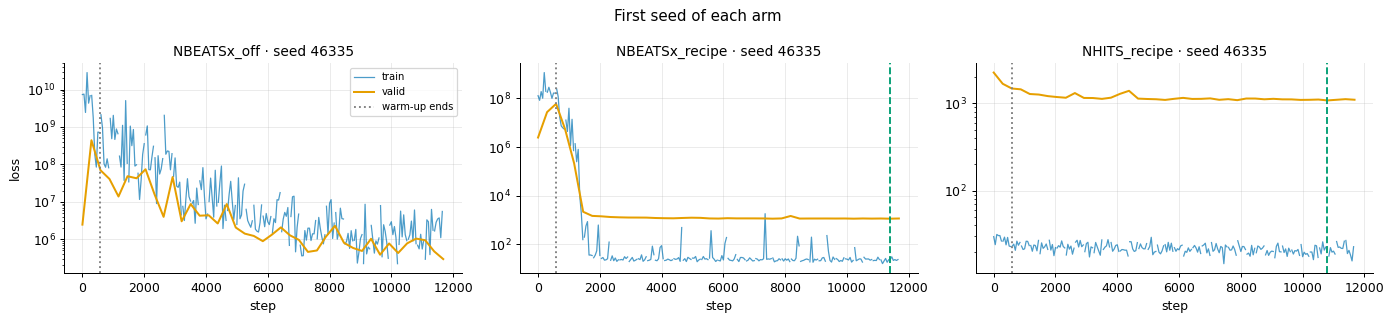

In [4]:
first_seeds = []
for runs in arms.values():
    first_seeds.append(runs[0])
gplt.plot_training(first_seeds, warmup=gd.warmup_steps(max_steps), title="First seed of each arm")

<!-- DRAFT: Graeme to edit -->
## 4. Accuracy and seed spread

Each seed is scored on its own: its median RMSSE over the 2,000 series. The table gives the
middle of the three, and the gap between the best and worst seed.

In [5]:
forecasts = {name: gd.seed_forecasts(runs) for name, runs in arms.items()}
seed_scores = {}
health = []
for name, runs in arms.items():
    seed_scores[name] = gd.seed_medians(runs, test, train)
    for run in runs:
        health.append({**run["summary"], "arm": name})

spread = pd.DataFrame({name: {"median of seed medians": s.median(),
                              "seed spread (max - min)": s.max() - s.min()}
                       for name, s in seed_scores.items()}).T
spread.round(3)

,median of seed medians,seed spread (max - min)
NBEATSx_off,0.808,0.052
NBEATSx_recipe,0.570,0.012
NHITS_recipe,0.550,0.009


<!-- DRAFT: Graeme to edit -->
The arm comparison chart puts the seeds side by side. Left: every seed's validation curve,
one colour per arm. Then a box per arm for oscillation and for median RMSSE, with each black
dot one seed. Tight boxes mean the seeds agree.

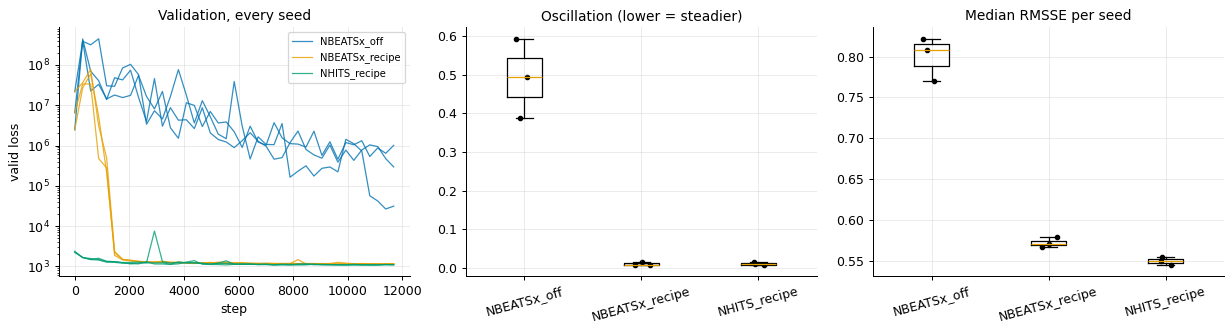

In [6]:
gplt.plot_arm_comparison(arms, metrics=seed_scores)

<!-- DRAFT: Graeme to edit -->
### Reading the result

* Compare the gap between arms with the seed spread inside each arm. A gap smaller than the
  spread is not a finding.
* Median RMSSE: recipe ≈ __, off ≈ __, NHITS ≈ __. Seed spread: recipe ≈ __, off ≈ __.
  <!-- TODO: fill after GPU run -->
* In the research the bigger prize was **stability**, not accuracy [100k set].

*Reference run: full panel, GPU box, 3 seeds. Exact numbers vary with seed and hardware; the
reading should not.*

<!-- DRAFT: Graeme to edit -->
### Training health

We screen runs on the validation curve only, never on price response (§4, [method]):

* `oscillation`: how much validation loss jumps between checks late in training;
* `best_frac`: where the kept weights came from. Above ≈ 0.65 suggests the budget is short;
* `neg_share`: the share of negative forecasts. Discard a run above 10%.

In [7]:
health_cols = ["arm", "seed", "fit_seconds", "oscillation", "best_frac", "final_over_best",
               "neg_share"]
pd.DataFrame(health)[health_cols].round(3)

,arm,seed,fit_seconds,oscillation,best_frac,final_over_best,neg_share
0,NBEATSx_off,46335,506.2,0.493,NaN,1.000,0.075
1,NBEATSx_off,11207,505.5,0.389,NaN,1.180,0.060
2,NBEATSx_off,90218,516.0,0.593,NaN,2.207,0.085
3,NBEATSx_recipe,46335,499.6,0.015,0.972,1.019,0.013
4,NBEATSx_recipe,11207,509.4,0.007,0.947,1.009,0.020
5,NBEATSx_recipe,90218,511.7,0.008,0.947,1.010,0.018
6,NHITS_recipe,46335,247.4,0.016,0.922,1.018,0.024
7,NHITS_recipe,11207,252.2,0.009,0.623,1.018,0.020
8,NHITS_recipe,90218,248.7,0.007,0.847,1.014,0.015


<!-- DRAFT: Graeme to edit -->
## 5. On the board, and against the Day 1 models

The three seeds of each arm are averaged into one forecast and recorded. We then compare the
recipe model with LightGBM and SeasonalNaive using the charts from notebook 00.

In [8]:
board_fcst = forecasts["NBEATSx_off"][["unique_id", "ds"]]
for name in arms:
    board_fcst = board_fcst.merge(forecasts[name][["unique_id", "ds", f"{name}_mean"]],
                                  on=["unique_id", "ds"])
fit_seconds = {}
for name, runs in arms.items():
    fit_seconds[f"{name}_mean"] = gd.summaries(runs)["fit_seconds"].mean()
gd.save_forecasts(board_fcst, "01_recipe")
gd.record(board_fcst, test, train, lab="01 recipe (3-seed mean)", fit_seconds=fit_seconds,
          notes="fit_seconds is per seed")
gd.median_board()

,model,median_rmsse,mean_rmsse,wape,n_series,lab,fit_seconds
0,NHITS_recipe_mean,0.539,1.063,0.251,1999,01 recipe (3-seed mean),249.433
1,NBEATSx_recipe_mean,0.568,1.114,0.286,1999,01 recipe (3-seed mean),506.900
2,LightGBM,0.569,1.161,0.295,1999,00 baselines (full panel),NaN
3,AutoETS,0.708,1.285,0.426,1999,00 baselines (full panel),NaN
4,Naive,0.771,1.332,0.470,1999,00 baselines (full panel),NaN
5,NBEATSx_off_mean,0.773,741.411,8.717,1999,01 recipe (3-seed mean),509.233
6,SeasonalNaive,0.929,1.525,0.438,1999,00 baselines (full panel),NaN


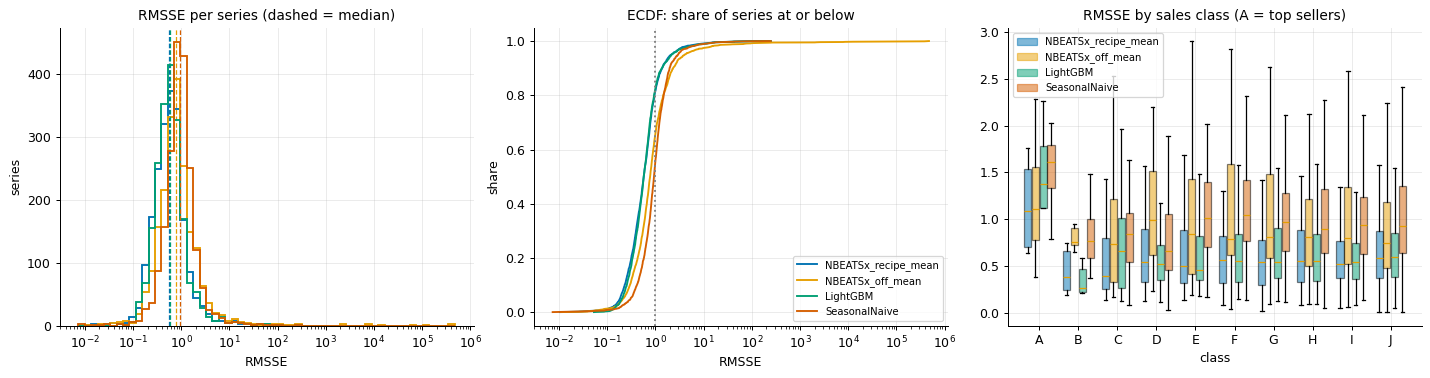

In [9]:
baselines = pd.read_parquet(gd.FORECAST_DIR / "00_baselines.parquet")
both = board_fcst.merge(baselines, on=["unique_id", "ds"])
rmsse = gd.per_series(gd.score(both, test, train))
gplt.plot_error_dist(rmsse, info, models=["NBEATSx_recipe_mean", "NBEATSx_off_mean",
                                          "LightGBM", "SeasonalNaive"])

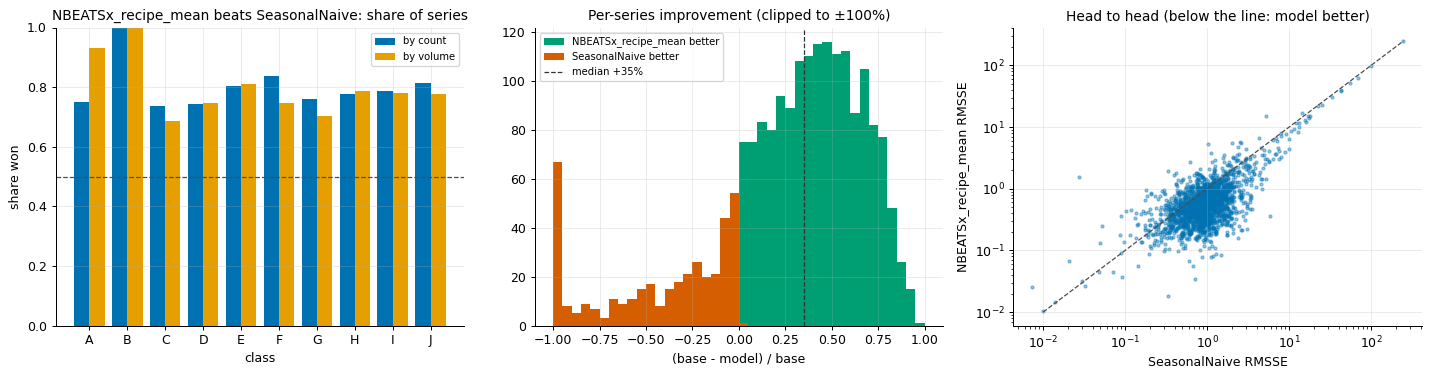

,win_share,win_share_volume,n
sale_class,,,
A,0.750,0.931,4.0
B,1.000,1.000,10.0
C,0.737,0.685,19.0
D,0.742,0.746,31.0
E,0.804,0.810,46.0
F,0.836,0.748,67.0
G,0.760,0.702,96.0
H,0.777,0.788,148.0
I,0.788,0.781,259.0


In [10]:
gplt.plot_wins(rmsse, info, model="NBEATSx_recipe_mean", baseline="SeasonalNaive")

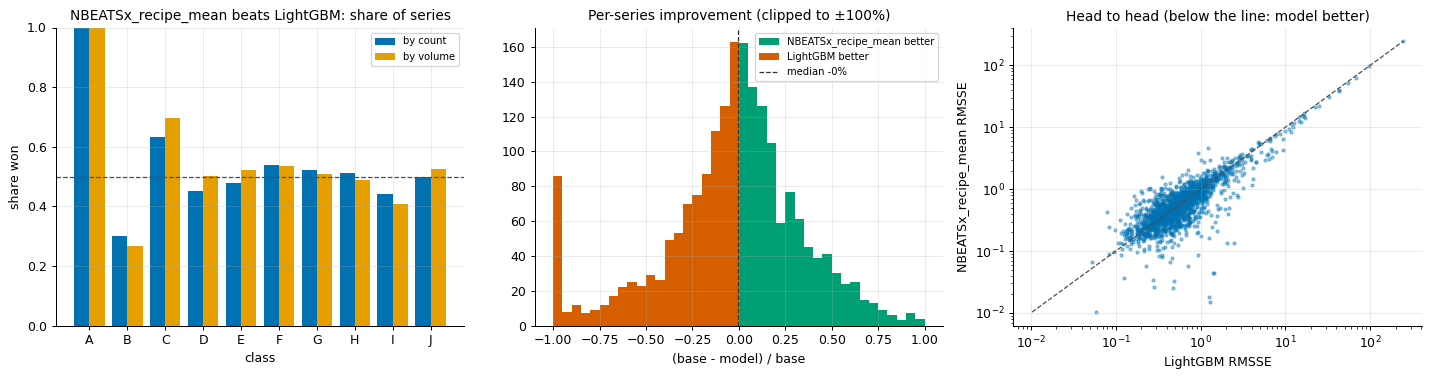

,win_share,win_share_volume,n
sale_class,,,
A,1.000,1.000,4.0
B,0.300,0.267,10.0
C,0.632,0.698,19.0
D,0.452,0.501,31.0
E,0.478,0.522,46.0
F,0.537,0.534,67.0
G,0.521,0.507,96.0
H,0.514,0.490,148.0
I,0.440,0.408,259.0


In [11]:
gplt.plot_wins(rmsse, info, model="NBEATSx_recipe_mean", baseline="LightGBM")

<!-- DRAFT: Graeme to edit -->
### Reading the result

* Against SeasonalNaive the recipe model should win most series. Against LightGBM, look at
  the by-volume bars: does the network win where the sales are?
* Recipe model: median RMSSE ≈ __ (mean ≈ __); LightGBM: median ≈ __ (mean ≈ __).
  <!-- TODO: fill after GPU run -->

*Exact numbers vary with seed and hardware; the reading should not.*

<!-- DRAFT: Graeme to edit -->
## 6. The example series, with forecasts

The examples from notebook 00, with the recipe model and LightGBM dashed over the test
window. Each title gives the forecast bias over the 14 weeks.

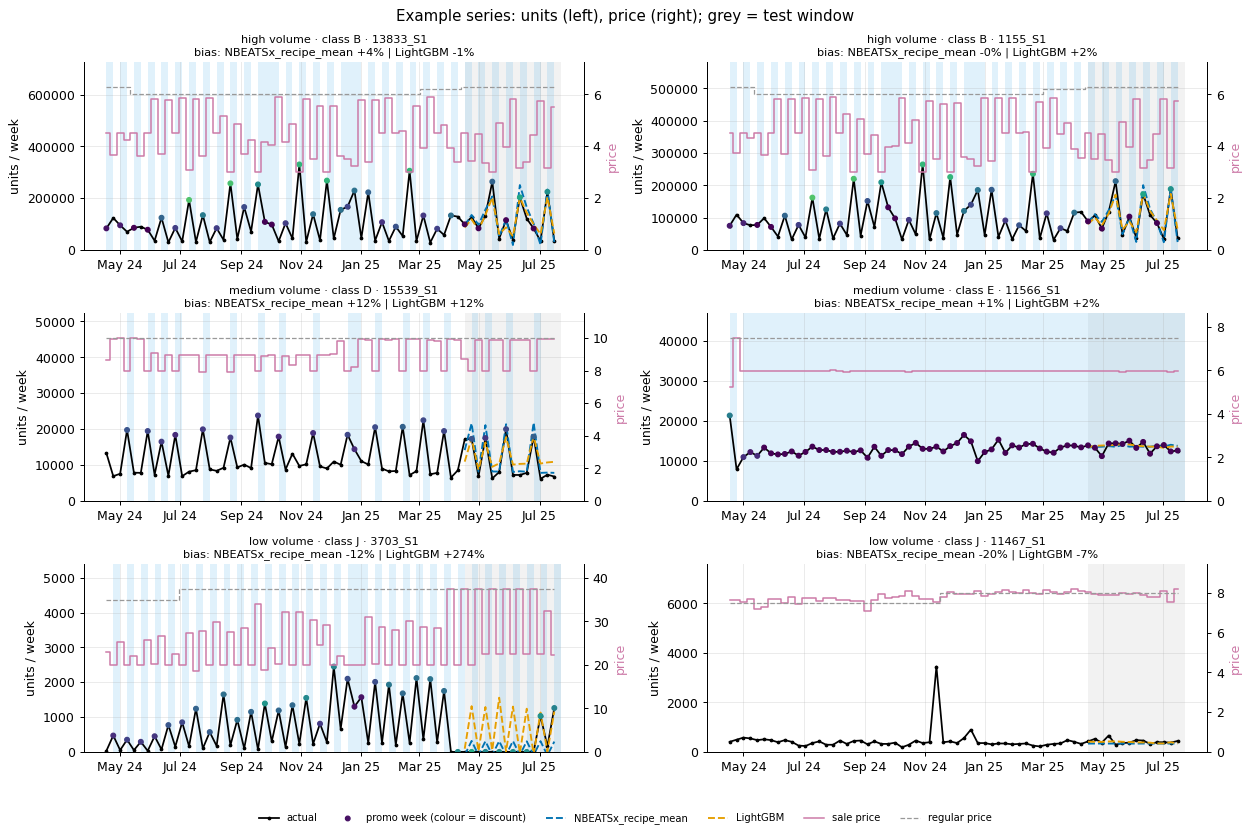

In [12]:
gplt.plot_series_price(panel, baselines_cfg["examples"], both,
                       models=["NBEATSx_recipe_mean", "LightGBM"])

In [13]:
best = "NBEATSx_recipe"
gd.save_config("01_recipe", {
    "model": "NBEATSx",
    "params": params,
    "recipe": True,
    "y_shift": gd.Y_SHIFT,
    "futr_exog": recipe_data.futr_exog,
    "stat_exog": recipe_data.stat_exog,
    "max_steps": max_steps,
    "seeds": gd.SEEDS,
    "minutes_per_fit": {n: round(sec / 60, 2) for n, sec in fit_seconds.items()},
    "median_rmsse": {n: float(rmsse[f"{n}_mean"].median()) for n in arms},
    "seed_spread": spread["seed spread (max - min)"].round(4).to_dict(),
    "saved_model": "01_nbeatsx_recipe",
    "selected": best,
})

PosixPath('/home/gdavidson/code/time-series-forecasting-bootcamp/results/day2_full/configs/01_recipe.json')

<!-- DRAFT: Graeme to edit -->
## Discussion

* Does the recipe win on accuracy, on seed spread, or both? Which would you rather have when
  every later notebook compares settings that differ by a little?
* Look at `best_frac`. If the kept weights come from the very end, the budget is too short.
  If they come from the middle, the run kept going after its best. Which do you see?
* The minutes per fit in `01_recipe` size the search in notebook 02. How many fits could you
  afford in an afternoon?

**Try it:** set `warmup_frac=0` in `gd.recipe_kwargs` and look at the first few hundred steps
of the training curve.